# 03 - Segmentation 2D HDF5 : resultats numeriques

Ce notebook presente une experience reproductible sur les coupes HDF5 BraTS. Les quatre modalites MRI sont les canaux d entree et les trois canaux du masque sont fusionnes en une cible binaire (`masque > 0`).

La methode numerique est un U-Net 2D optimise par descente de gradient Adam avec une perte d entropie croisee. Les donnees sont separees **par volume** afin d eviter la fuite de donnees. Les resultats sont mesures par Dice, IoU, precision et rappel, puis compares a une baseline qui predit toujours le fond.

> `QUICK_RUN=True` utilise un sous-ensemble fixe pour une demonstration rapide. Mettre `QUICK_RUN=False` pour l experience complete.

In [12]:
from pathlib import Path
import csv
import json
import sys

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = REPO_ROOT / "data/raw/data"
RESULT_ROOT = REPO_ROOT / "results/figures/segmentation"
RESULT_ROOT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO_ROOT / "src"))
from brain_mri_fem.segmentation import UNet2D, dice, iou
from brain_mri_fem.segmentation.metrics import precision_recall
from brain_mri_fem.utils import seed_everything

SEED = 42
QUICK_RUN = True
MAX_VOLUMES = 12 if QUICK_RUN else None
MAX_SLICES_PER_VOLUME = 16 if QUICK_RUN else None
EPOCHS = 3 if QUICK_RUN else 20
BATCH_SIZE = 8
LEARNING_RATE = 1e-3
seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cpu


In [13]:
files = sorted(DATA_ROOT.glob("*.h5"))
if not files:
    raise FileNotFoundError(f"Aucun fichier HDF5 dans {DATA_ROOT}")

def volume_id(path):
    return path.stem.rsplit("_slice_", 1)[0]

by_volume = {}
for path in files:
    by_volume.setdefault(volume_id(path), []).append(path)
volume_ids = sorted(by_volume)
rng = np.random.default_rng(SEED)
rng.shuffle(volume_ids)
if MAX_VOLUMES is not None:
    volume_ids = volume_ids[:MAX_VOLUMES]
n = len(volume_ids)
n_train = max(1, int(0.70 * n))
n_val = max(1, int(0.15 * n))
split_ids = {
    "train": volume_ids[:n_train],
    "val": volume_ids[n_train:n_train + n_val],
    "test": volume_ids[n_train + n_val:],
}
if not split_ids["test"]:
    split_ids["test"] = split_ids["val"][-1:]

def paths_for(split):
    selected = []
    for current_id in split_ids[split]:
        candidates = sorted(by_volume[current_id])
        if MAX_SLICES_PER_VOLUME is not None:
            candidates = candidates[:MAX_SLICES_PER_VOLUME]
        selected.extend(candidates)
    return selected

split_paths = {name: paths_for(name) for name in split_ids}
print(f"Volumes: {len(volume_ids)} | train/val/test: {[len(split_ids[name]) for name in ('train', 'val', 'test')]}")
print(f"Coupes: {[len(split_paths[name]) for name in ('train', 'val', 'test')]}")

Volumes: 12 | train/val/test: [8, 1, 3]
Coupes: [128, 16, 48]


In [14]:
def normalize_channels(image):
    image = np.asarray(image, dtype=np.float32)
    result = np.zeros_like(image)
    for channel in range(image.shape[-1]):
        values = image[:, :, channel]
        active = values != 0
        if active.any():
            result[:, :, channel][active] = (values[active] - values[active].mean()) / max(values[active].std(), 1e-6)
    return result

class H5Slices(Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with h5py.File(self.paths[index], "r") as handle:
            image = normalize_channels(handle["image"][:])
            target = handle["mask"][:].any(axis=-1).astype(np.int64)
        return torch.from_numpy(image.transpose(2, 0, 1)), torch.from_numpy(target)

loaders = {
    "train": DataLoader(H5Slices(split_paths["train"]), batch_size=BATCH_SIZE, shuffle=True, num_workers=0),
    "val": DataLoader(H5Slices(split_paths["val"]), batch_size=BATCH_SIZE, shuffle=False, num_workers=0),
    "test": DataLoader(H5Slices(split_paths["test"]), batch_size=BATCH_SIZE, shuffle=False, num_workers=0),
}
print("Forme image:", H5Slices(split_paths["train"])[0][0].shape)

Forme image: torch.Size([4, 240, 240])


In [15]:
def evaluate(model, loader):
    model.eval()
    losses, predictions, targets = [], [], []
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        for images, batch_targets in loader:
            logits = model(images.to(device))
            losses.append(float(criterion(logits, batch_targets.to(device)).cpu()))
            predictions.append(logits.argmax(dim=1).cpu().numpy())
            targets.append(batch_targets.numpy())
    prediction = np.concatenate(predictions).astype(bool)
    target = np.concatenate(targets).astype(bool)
    tumor_slices = target.reshape(target.shape[0], -1).any(axis=1)
    precision, recall = precision_recall(prediction, target)
    metrics = {
        "loss": float(np.mean(losses)),
        "dice": dice(prediction, target),
        "iou": iou(prediction, target),
        "precision": precision,
        "recall": recall,
        "tumor_slice_fraction": float(tumor_slices.mean()),
        "tumor_slice_dice": dice(prediction[tumor_slices], target[tumor_slices]) if tumor_slices.any() else 0.0,
    }
    return metrics

model = UNet2D(in_channels=4, out_channels=2, channels=(8, 16, 32)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss()
history = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    train_losses = []
    for images, targets in loaders["train"]:
        optimizer.zero_grad()
        loss = criterion(model(images.to(device)), targets.to(device))
        loss.backward()
        optimizer.step()
        train_losses.append(float(loss.detach().cpu()))
    val_metrics = evaluate(model, loaders["val"])
    row = {"epoch": epoch, "train_loss": float(np.mean(train_losses)), **val_metrics}
    history.append(row)
    print(f"Epoch {epoch:02d}/{EPOCHS} | train_loss={row['train_loss']:.4f} | val_loss={row['loss']:.4f} | val_dice={row['dice']:.4f} | val_iou={row['iou']:.4f}")

Epoch 01/3 | train_loss=0.6316 | val_loss=0.6408 | val_dice=0.0000 | val_iou=0.0000
Epoch 02/3 | train_loss=0.5153 | val_loss=0.5442 | val_dice=0.0000 | val_iou=0.0000
Epoch 03/3 | train_loss=0.4457 | val_loss=0.4656 | val_dice=0.0000 | val_iou=0.0000


In [16]:
test_metrics = evaluate(model, loaders["test"])
test_targets = []
for _, targets in loaders["test"]:
    test_targets.append(targets.numpy().astype(bool))
test_target = np.concatenate(test_targets)
empty_prediction = np.zeros_like(test_target, dtype=bool)
precision, recall = precision_recall(empty_prediction, test_target)
baseline = {
    "dice": dice(empty_prediction, test_target),
    "iou": iou(empty_prediction, test_target),
    "precision": precision,
    "recall": recall,
}
print("\nResultats sur le jeu de test")
print(f"{'Methode':<18} {'Dice':>8} {'IoU':>8} {'Precision':>10} {'Rappel':>8}")
for name, result in (("Baseline fond", baseline), ("U-Net 2D", test_metrics)):
    print(f"{name:<18} {result['dice']:8.4f} {result['iou']:8.4f} {result['precision']:10.4f} {result['recall']:8.4f}")
print(f"Coupes tumorales dans le test: {test_metrics['tumor_slice_fraction']:.2%}")
print(f"Dice sur coupes tumorales: {test_metrics['tumor_slice_dice']:.4f}")


Resultats sur le jeu de test
Methode                Dice      IoU  Precision   Rappel
Baseline fond        0.0000   0.0000     1.0000   0.0000
U-Net 2D             0.8074   0.6770     0.7071   0.9408
Coupes tumorales dans le test: 35.42%
Dice sur coupes tumorales: 0.8930


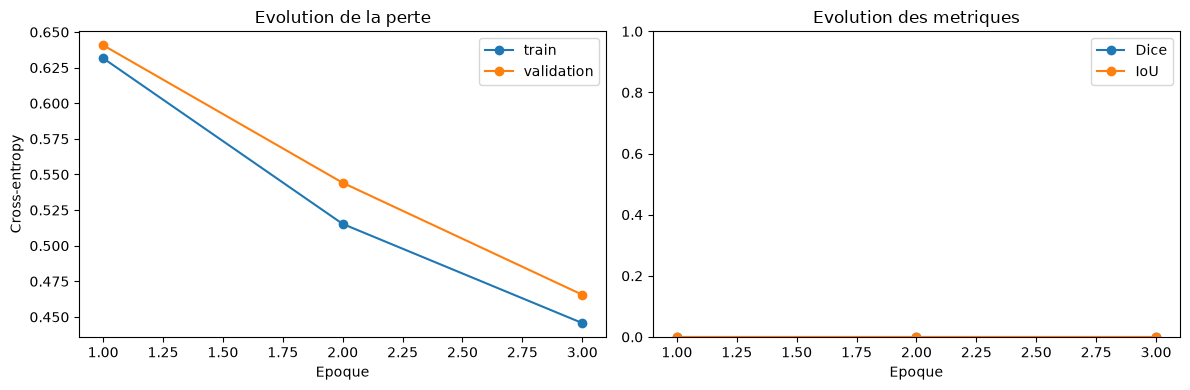

In [17]:
epochs = [row["epoch"] for row in history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, [row["train_loss"] for row in history], marker="o", label="train")
axes[0].plot(epochs, [row["loss"] for row in history], marker="o", label="validation")
axes[0].set_title("Evolution de la perte")
axes[0].set_xlabel("Epoque")
axes[0].set_ylabel("Cross-entropy")
axes[0].legend()
axes[1].plot(epochs, [row["dice"] for row in history], marker="o", label="Dice")
axes[1].plot(epochs, [row["iou"] for row in history], marker="o", label="IoU")
axes[1].set_title("Evolution des metriques")
axes[1].set_xlabel("Epoque")
axes[1].set_ylim(0, 1)
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULT_ROOT / "unet2d_h5_training_curves.png", dpi=150)
plt.show()

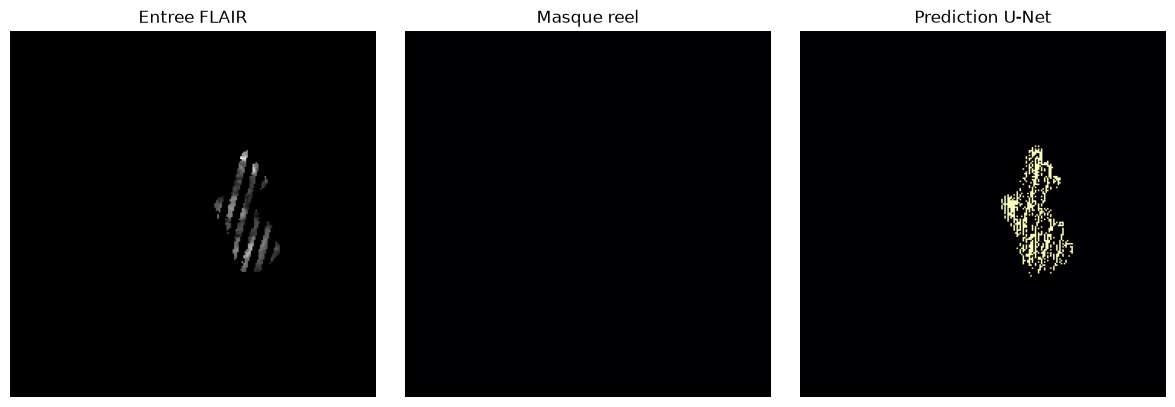

Metriques sauvegardees dans results/segmentation_2d_metrics.json et .csv


In [18]:
sample_image, sample_target = H5Slices(split_paths["test"])[0]
with torch.no_grad():
    sample_prediction = model(sample_image.unsqueeze(0).to(device)).argmax(dim=1).cpu().numpy()[0]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(sample_image[0], cmap="gray")
axes[0].set_title("Entree FLAIR")
axes[1].imshow(sample_target, cmap="magma")
axes[1].set_title("Masque reel")
axes[2].imshow(sample_prediction, cmap="magma")
axes[2].set_title("Prediction U-Net")
for axis in axes:
    axis.axis("off")
fig.tight_layout()
fig.savefig(RESULT_ROOT / "unet2d_h5_prediction.png", dpi=150)
plt.show()

result_payload = {
    "seed": SEED,
    "quick_run": QUICK_RUN,
    "epochs": EPOCHS,
    "device": str(device),
    "volumes": split_ids,
    "history": history,
    "test_unet2d": test_metrics,
    "test_baseline_background": baseline,
}
(REPO_ROOT / "results/segmentation_2d_metrics.json").write_text(json.dumps(result_payload, indent=2), encoding="utf-8")
with (REPO_ROOT / "results/segmentation_2d_metrics.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=["method", "dice", "iou", "precision", "recall"])
    writer.writeheader()
    writer.writerow({"method": "background_baseline", **{key: baseline[key] for key in writer.fieldnames[1:]}})
    writer.writerow({"method": "unet2d", **{key: test_metrics[key] for key in writer.fieldnames[1:]}})
print("Metriques sauvegardees dans results/segmentation_2d_metrics.json et .csv")